# Ensemble Learning on the UCI Breast Cancer Dataset

**Aim:** Train and compare AdaBoost and Gradient Boosting, examine feature importance, and plot ROC curves for four ensemble classifiers.

### What this notebook does
1. Loads **UCI Breast Cancer dataset 14**.
2. Handles missing categorical values and one-hot encodes the predictors.
3. Trains `AdaBoostClassifier(n_estimators=200)` and `GradientBoostingClassifier(n_estimators=200)` and reports test accuracy and total training time in one table.
4. Draws three side-by-side horizontal feature-importance charts for Random Forest, AdaBoost, and Gradient Boosting.
5. Checks whether the top-three original features agree across those three models.
6. Draws ROC curves with AUC values for four ensemble methods: Random Forest, Extra Trees, AdaBoost, and Gradient Boosting.

> **Interpretation of the brief:** It explicitly names AdaBoost and Gradient Boosting, but also asks for three feature-importance panels and ROC curves for four methods. To complete those plots, this notebook adds Random Forest and Extra Trees as supplementary ensemble models. The required accuracy/training-time comparison table contains only AdaBoost and Gradient Boosting.

### Dataset note
The supplied UCI link is dataset **14**, the Ljubljana breast-cancer recurrence dataset (286 records and 9 predictor attributes). Its target classes are `no-recurrence-events` and `recurrence-events`. The predictors are categorical and some values are missing, so preprocessing is required. This is **not** the Wisconsin Diagnostic Breast Cancer dataset.

**Reproducibility:** A fixed random seed (`42`) and a stratified 80:20 train/test split are used. Since the dataset is small, results can vary with a different split.

**Source:** Zwitter, M. & Soklic, M. (1988). *Breast Cancer* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C51P4M


## 1. Install and import libraries

Run the installation cell once in the active Jupyter environment. The UCI repository helper downloads the dataset directly from UCI.

In [3]:
# %pip install -q ucimlrepo scikit-learn pandas numpy matplotlib

In [4]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_ESTIMATORS = 200

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the UCI dataset

The preferred method uses `ucimlrepo.fetch_ucirepo(id=14)`. A direct UCI file URL and a local-file fallback are included in case the helper package or network is unavailable.

In [5]:
# Column names for the original UCI breast-cancer.data file (no header row).
UCI_COLUMNS = [
    "age", "menopause", "tumor-size", "inv-nodes", "node-caps",
    "deg-malig", "breast", "breast-quad", "irradiat", "Class"
]

try:
    from ucimlrepo import fetch_ucirepo

    breast_cancer = fetch_ucirepo(id=14)
    X = breast_cancer.data.features.copy()
    y_frame = breast_cancer.data.targets.copy()
    print("Dataset loaded using ucimlrepo (UCI dataset id=14).")

except Exception as fetch_error:
    print("ucimlrepo download was not successful:", repr(fetch_error))
    print("Trying the original UCI data-file URL...")

    data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer/breast-cancer.data"
    try:
        raw_df = pd.read_csv(
            data_url,
            header=None,
            names=UCI_COLUMNS,
            na_values="?",
        )
        X = raw_df.drop(columns="Class").copy()
        y_frame = raw_df[["Class"]].copy()
        print("Dataset loaded from the original UCI data-file URL.")
    except Exception as url_error:
        local_path = Path("breast-cancer.data")
        if not local_path.exists():
            raise RuntimeError(
                "Could not download the dataset. Download breast-cancer.data from "
                "the UCI dataset page (https://archive.ics.uci.edu/dataset/14/breast+cancer), "
                "place it beside this notebook, and rerun this cell."
            ) from url_error
        raw_df = pd.read_csv(
            local_path,
            header=None,
            names=UCI_COLUMNS,
            na_values="?",
        )
        X = raw_df.drop(columns="Class").copy()
        y_frame = raw_df[["Class"]].copy()
        print("Dataset loaded from local file: breast-cancer.data")

# Normalize missing markers and convert all predictors to categorical strings.
# Doing the conversion after replacing '?' avoids treating missing values as a category.
X = X.replace(r"^\s*\?\s*$", np.nan, regex=True)
for column in X.columns:
    X[column] = X[column].map(
        lambda value: str(value).strip() if pd.notna(value) else np.nan
    )

# Target: 0 = no recurrence, 1 = recurrence.
y_raw = y_frame.iloc[:, 0].astype(str).str.strip()
y = y_raw.map({"no-recurrence-events": 0, "recurrence-events": 1})

if y.isna().any():
    unknown_labels = sorted(y_raw[y.isna()].unique().tolist())
    raise ValueError(f"Unexpected target labels found: {unknown_labels}")

# Keep target and predictors aligned and use a normal integer index.
X = X.reset_index(drop=True)
y = y.reset_index(drop=True).astype(int)

print(f"\nDataset shape: {X.shape[0]} rows × {X.shape[1]} predictors")
print("Target distribution (0 = no recurrence, 1 = recurrence):")
print(y.value_counts().sort_index().rename(index={0: "no-recurrence-events", 1: "recurrence-events"}))
print("\nMissing values per predictor before imputation:")
display(X.isna().sum().to_frame("Missing values"))

display(X.head())

Dataset loaded using ucimlrepo (UCI dataset id=14).

Dataset shape: 286 rows × 9 predictors
Target distribution (0 = no recurrence, 1 = recurrence):
Class
no-recurrence-events    201
recurrence-events        85
Name: count, dtype: int64

Missing values per predictor before imputation:


,Missing values
age,0
menopause,0
tumor-size,0
inv-nodes,0
node-caps,8
deg-malig,0
breast,0
breast-quad,1
irradiat,0


,age,menopause,tumor-size,inv-nodes,node-caps,deg-malig,breast,breast-quad,irradiat
0,30-39,premeno,30-34,0-2,no,3,left,left_low,no
1,40-49,premeno,20-24,0-2,no,2,right,right_up,no
2,40-49,premeno,20-24,0-2,no,2,left,left_low,no
3,60-69,ge40,15-19,0-2,no,2,right,left_up,no
4,40-49,premeno,0-4,0-2,no,2,right,right_low,no


## 3. Split the data and define preprocessing

All nine predictors are treated as categorical variables. Missing values are filled using the most frequent training-set value, then categories are one-hot encoded. The preprocessing is placed inside each model pipeline so the test set is not used to fit the imputer or encoder.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training rows: {len(X_train)}")
print(f"Testing rows : {len(X_test)}")
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).sort_index())


def make_model_pipeline(classifier):
    """Create a leakage-safe preprocessing + classifier pipeline."""
    categorical_preprocessor = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[("categorical", categorical_preprocessor, X.columns.tolist())],
        remainder="drop",
    )

    return Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier),
        ]
    )

Training rows: 228
Testing rows : 58

Training target proportions:
Class
0    0.701754
1    0.298246
Name: proportion, dtype: float64

Testing target proportions:
Class
0    0.706897
1    0.293103
Name: proportion, dtype: float64


## 4. Train the four ensemble classifiers

The required AdaBoost and Gradient Boosting models use exactly 200 estimators. Random Forest and Extra Trees are added to satisfy the four-model ROC requirement and provide the third feature-importance chart. Training time is measured around the complete pipeline fit, including preprocessing.

In [7]:
model_definitions = {
    "Random Forest": RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=N_ESTIMATORS,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
    ),
}

models = {}
training_records = []

for model_name, estimator in model_definitions.items():
    pipeline = make_model_pipeline(estimator)

    start_time = time.perf_counter()
    pipeline.fit(X_train, y_train)
    elapsed_seconds = time.perf_counter() - start_time

    y_pred = pipeline.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred)

    models[model_name] = pipeline
    training_records.append(
        {
            "Model": model_name,
            "Test Accuracy": test_accuracy,
            "Training Time (s)": elapsed_seconds,
        }
    )

    print(
        f"{model_name:18s} | accuracy = {test_accuracy:.4f} "
        f"| training time = {elapsed_seconds:.6f} s"
    )

all_model_results = pd.DataFrame(training_records).set_index("Model")
print("\nResults for all four models (additional context):")
display(all_model_results.style.format({
    "Test Accuracy": "{:.4f}",
    "Training Time (s)": "{:.6f}",
}))

Random Forest      | accuracy = 0.7241 | training time = 0.614002 s
Extra Trees        | accuracy = 0.7241 | training time = 0.269201 s
AdaBoost           | accuracy = 0.7241 | training time = 0.303089 s
Gradient Boosting  | accuracy = 0.6897 | training time = 0.205376 s

Results for all four models (additional context):


,Test Accuracy,Training Time (s)
Model,,
Random Forest,0.7241,0.614002
Extra Trees,0.7241,0.269201
AdaBoost,0.7241,0.303089
Gradient Boosting,0.6897,0.205376


## 5. Required comparison: AdaBoost vs Gradient Boosting

This is the requested comparison table. Training time is reported in seconds and includes fitting the preprocessing pipeline.

In [8]:
comparison_table = all_model_results.loc[
    ["AdaBoost", "Gradient Boosting"],
    ["Test Accuracy", "Training Time (s)"],
].copy()

display(comparison_table.style.format({
    "Test Accuracy": "{:.4f}",
    "Training Time (s)": "{:.6f}",
}))

,Test Accuracy,Training Time (s)
Model,,
AdaBoost,0.7241,0.303089
Gradient Boosting,0.6897,0.205376


## 6. Extract feature importances

One-hot encoding expands each original predictor into several category columns. To report importance at the original-feature level, this cell **sums the importances of all one-hot columns belonging to the same original predictor**. This makes the three charts comparable and keeps the feature names meaningful. The UCI dataset has nine original predictors, so each chart will show all nine (the maximum available even though the task says top 10).

In [9]:
def original_feature_importances(fitted_pipeline, original_feature_names):
    """Aggregate one-hot encoded importances back to original predictors."""
    classifier = fitted_pipeline.named_steps["classifier"]
    encoded_importances = np.asarray(classifier.feature_importances_, dtype=float)

    categorical_pipeline = (
        fitted_pipeline.named_steps["preprocessor"]
        .named_transformers_["categorical"]
    )
    encoder = categorical_pipeline.named_steps["onehot"]

    grouped = {}
    cursor = 0
    for feature_name, categories in zip(original_feature_names, encoder.categories_):
        number_of_encoded_columns = len(categories)
        grouped[feature_name] = float(
            encoded_importances[cursor:cursor + number_of_encoded_columns].sum()
        )
        cursor += number_of_encoded_columns

    if cursor != len(encoded_importances):
        raise ValueError(
            "The encoded feature count does not match the fitted feature-importance vector."
        )

    return pd.Series(grouped, name="Importance").sort_values(ascending=False)


importance_models = ["Random Forest", "AdaBoost", "Gradient Boosting"]
importance_scores = {
    name: original_feature_importances(models[name], X.columns.tolist())
    for name in importance_models
}

for name, scores in importance_scores.items():
    print(f"\n{name} — feature importance:")
    display(scores.to_frame())


Random Forest — feature importance:


,Importance
tumor-size,0.208862
breast-quad,0.141327
deg-malig,0.132683
age,0.127557
inv-nodes,0.115305
menopause,0.075692
breast,0.075009
node-caps,0.061977
irradiat,0.061588



AdaBoost — feature importance:


,Importance
tumor-size,0.485119
inv-nodes,0.211452
deg-malig,0.120709
breast-quad,0.074423
menopause,0.049287
age,0.027283
irradiat,0.015942
node-caps,0.015785
breast,0.000000



Gradient Boosting — feature importance:


,Importance
tumor-size,0.231052
breast-quad,0.174180
inv-nodes,0.167510
deg-malig,0.138019
age,0.101935
menopause,0.061166
node-caps,0.050601
breast,0.043362
irradiat,0.032176


## 7. Three side-by-side horizontal bar charts (top features)

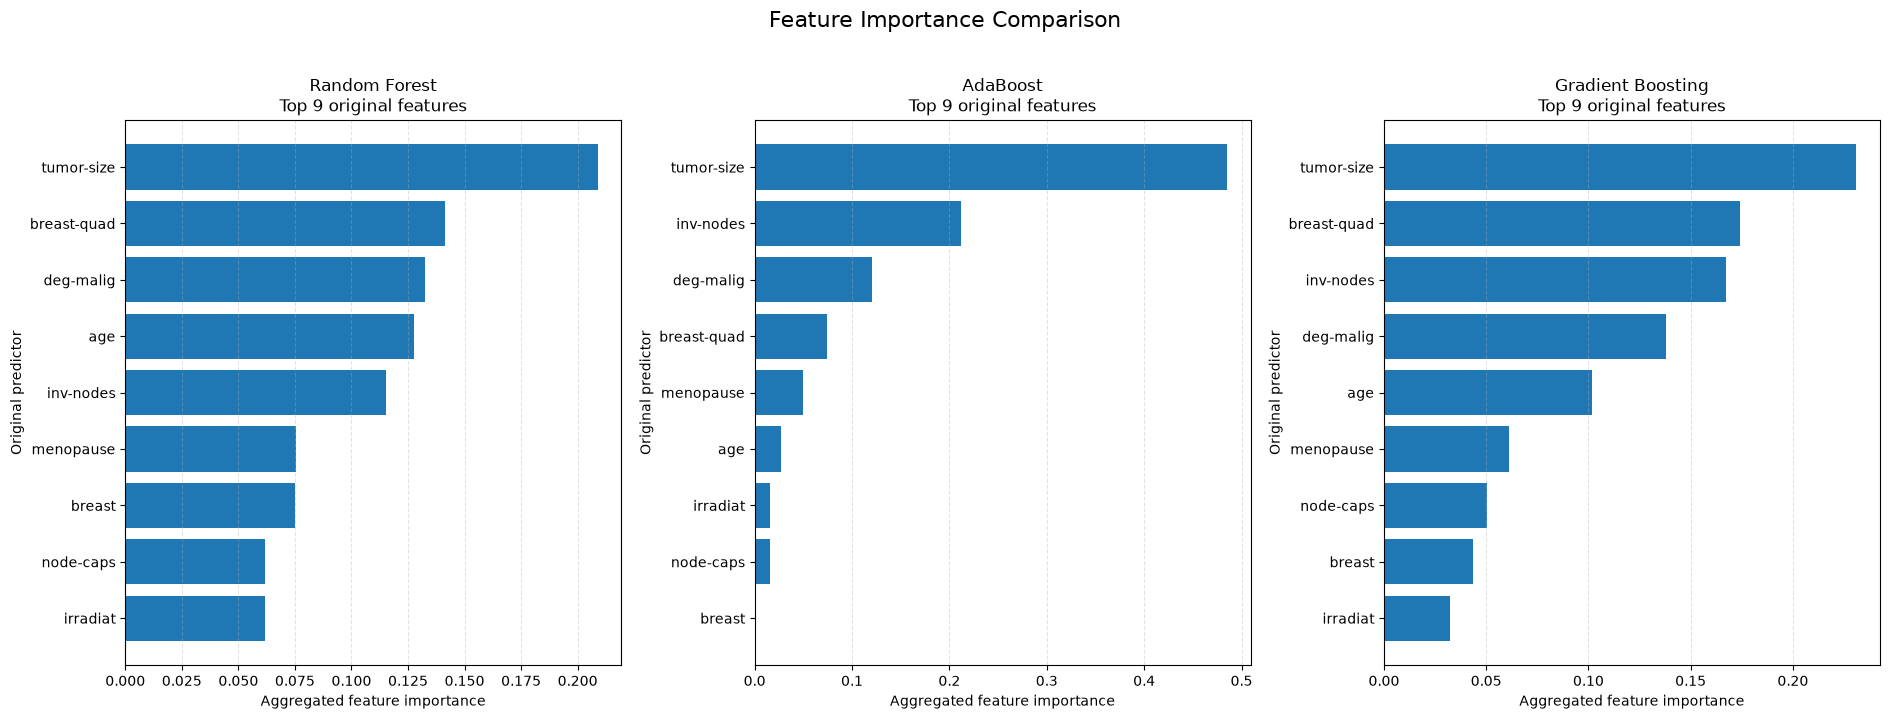

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 7), sharex=False)

for ax, model_name in zip(axes, importance_models):
    scores = importance_scores[model_name]
    top_scores = scores.head(min(10, len(scores))).sort_values(ascending=True)

    ax.barh(top_scores.index, top_scores.values)
    ax.set_title(f"{model_name}\nTop {len(top_scores)} original features")
    ax.set_xlabel("Aggregated feature importance")
    ax.set_ylabel("Original predictor")
    ax.grid(axis="x", linestyle="--", alpha=0.35)

fig.suptitle("Feature Importance Comparison", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 8. Do the top-three features agree?

The check reports both (a) whether the same three features appear, regardless of order, and (b) whether they appear in exactly the same ranking order.

In [11]:
top3_features = {
    model_name: list(scores.head(3).index)
    for model_name, scores in importance_scores.items()
}

for model_name, features in top3_features.items():
    print(f"{model_name} top 3: {features}")

top3_sets = [set(features) for features in top3_features.values()]
same_top3_set = all(features == top3_sets[0] for features in top3_sets[1:])
same_top3_order = all(
    features == list(top3_features.values())[0]
    for features in list(top3_features.values())[1:]
)
common_to_all = set.intersection(*top3_sets)

print("\nDo all three methods select the same top-3 features (order ignored)?", same_top3_set)
print("Do all three methods rank them in exactly the same order?", same_top3_order)
print("Features common to the top 3 of every method:", sorted(common_to_all))

Random Forest top 3: ['tumor-size', 'breast-quad', 'deg-malig']
AdaBoost top 3: ['tumor-size', 'inv-nodes', 'deg-malig']
Gradient Boosting top 3: ['tumor-size', 'breast-quad', 'inv-nodes']

Do all three methods select the same top-3 features (order ignored)? False
Do all three methods rank them in exactly the same order? False
Features common to the top 3 of every method: ['tumor-size']


## 9. ROC curves for all four ensemble methods

The positive class is `recurrence-events` (label 1). Each curve uses the predicted probability of that class. The AUC is included in the legend.

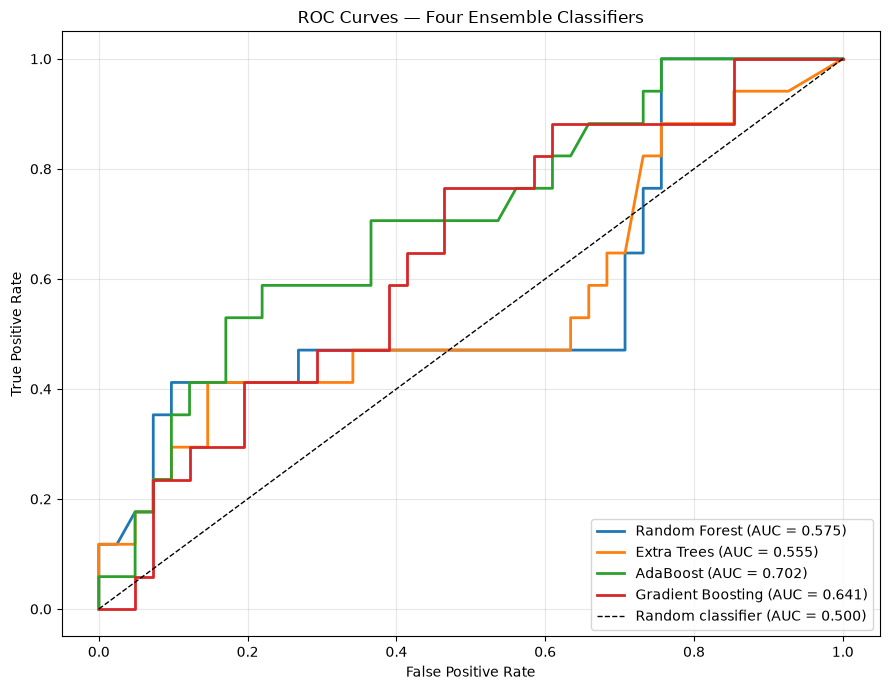

AUC values:


,ROC-AUC
Random Forest,0.5746
Extra Trees,0.5552
AdaBoost,0.7016
Gradient Boosting,0.6413


In [12]:
plt.figure(figsize=(9, 7))
roc_auc_results = {}

for model_name, fitted_pipeline in models.items():
    positive_probabilities = fitted_pipeline.predict_proba(X_test)[:, 1]
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test,
        positive_probabilities,
        pos_label=1,
    )
    model_auc = roc_auc_score(y_test, positive_probabilities)
    roc_auc_results[model_name] = model_auc

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"{model_name} (AUC = {model_auc:.3f})",
    )

plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random classifier (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Four Ensemble Classifiers")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("AUC values:")
display(pd.Series(roc_auc_results, name="ROC-AUC").to_frame().style.format("{:.4f}"))

## 10. Results summary and conclusion

After running the notebook, use the generated comparison table and plots to write your observations:

- **Accuracy/time:** Compare the two required models in the table. A higher accuracy does not automatically mean a better model if the difference is very small or unstable.
- **Feature importance:** Compare the three bar charts and quote the top-three agreement result printed in Section 8.
- **ROC-AUC:** The curve closer to the top-left corner and the larger AUC indicate better class separation on this particular test split.

**Important limitation:** This is a small, imbalanced historical recurrence dataset. The reported scores are a classroom model comparison, not evidence that these classifiers are suitable for clinical diagnosis or patient-care decisions. A stronger evaluation would use repeated stratified cross-validation and report uncertainty in addition to a single train/test split.

### Dataset citation
Zwitter, M. & Soklic, M. (1988). *Breast Cancer* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C51P4M
